In [1]:
# Decorrelation Analysis for Tokyo Bay
# Following the exact methodology of 08_Decorrelation_Analysis_v3.ipynb

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit
from scipy import stats
from pathlib import Path
import sys
import warnings

warnings.filterwarnings('ignore')

# Add project root to sys.path
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths
from scripts.data_loader import load_and_process_data
from scripts.mapping_config import MappingConfig

bay_name = "Tokyo Bay"

In [2]:
print("Loading data...")
merged_gdf = load_and_process_data(force_reload=False)

# Filter for Tokyo Bay
bay_gdf = merged_gdf[merged_gdf['watermass_name'] == bay_name].copy()
print(f"Total entries for {bay_name}: {len(bay_gdf)}")

# Representative month for Summer in Tokyo Bay
representative_month = 8  # August

# Parameters - matching notebook 08
min_periods = 15
r_crit_alpha = 0.01
distance_cutoff_km = 100

Loading data...
Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...


Total entries for Tokyo Bay: 9145


In [3]:
# Filter for Summer Bottom
summer_bottom = bay_gdf[
    (bay_gdf['season'] == 'Summer') & 
    (bay_gdf['saisuipoin'] == 2) &
    (bay_gdf['surveymont'] == representative_month)
].copy()
summer_bottom['do_'] = pd.to_numeric(summer_bottom['do_'], errors='coerce')
summer_bottom = summer_bottom.dropna(subset=['do_']).copy()

# Build yearly DO matrix (stations x years)
yearly_do_df = summer_bottom.groupby(['zettaicode', 'year'])['do_'].mean().unstack('year')

# Filter stations with insufficient temporal data
yearly_do_df = yearly_do_df[yearly_do_df.notna().sum(axis=1) >= min_periods]
print(f"Yearly DO DataFrame shape: {yearly_do_df.shape}")
print(f"  — {yearly_do_df.shape[0]} stations with >= {min_periods} valid years")
display(yearly_do_df.head())

Yearly DO DataFrame shape: (28, 40)
  — 28 stations with >= 15 valid years


year,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
zettaicode,,,,,,,,,,,,,,,,,,,,,
00000122,6.6,8.1,10.1,9.4,0.1,10.3,6.0,0.7,NaN,3.3,...,10.0,4.2,4.0,4.8,10.0,1.1,8.5,2.2,5.9,NaN
00000124,3.4,6.5,6.7,5.7,0.6,12.3,7.5,2.2,1.8,2.8,...,8.8,4.1,3.8,1.3,8.0,1.0,7.7,0.9,1.1,NaN
00000125,0.4,3.1,0.2,1.4,0.8,3.6,5.9,2.9,NaN,NaN,...,7.9,2.5,2.3,NaN,4.7,0.5,1.8,NaN,NaN,NaN
00000128,0.4,5.3,1.7,2.1,1.7,4.3,4.7,2.6,3.4,2.2,...,7.6,1.4,4.5,1.5,7.6,1.1,2.0,1.0,3.7,NaN
00000129,0.4,0.4,1.9,4.7,1.9,5.2,5.0,3.8,3.2,2.3,...,1.6,1.7,3.7,2.6,3.2,1.7,0.7,NaN,1.2,NaN


In [4]:
# Get station coordinates
station_coords = bay_gdf[['zettaicode', 'geometry']].drop_duplicates('zettaicode')
station_coords = station_coords[station_coords['zettaicode'].isin(yearly_do_df.index)]
station_coords = station_coords.set_index('zettaicode')

# Project to UTM Zone 53N (meter-based) for distance calculation
stns_utm = gpd.GeoDataFrame(station_coords, geometry='geometry', crs=bay_gdf.crs)
stns_utm = stns_utm.to_crs(epsg=32653)

# Calculate pairwise distance matrix in km
coords = np.array([(geom.x, geom.y) for geom in stns_utm['geometry']])
dist_matrix = cdist(coords, coords) / 1000.0
dist_matrix_km = pd.DataFrame(dist_matrix, index=stns_utm.index, columns=stns_utm.index)

print(f"Distance matrix shape: {dist_matrix_km.shape}")
print(f"Max inter-station distance: {dist_matrix_km.max().max():.1f} km")

Distance matrix shape: (28, 28)
Max inter-station distance: 51.0 km


In [5]:
# Gaussian model with offset — matches notebook 08 exactly
# r(x) = A * exp(-(x/dx)^2) + B, where B = 1 - A
def gaussian_model_with_offset(x, A, dx):
    """Gaussian decay with offset, constrained: A + B = 1"""
    B = 1 - A
    return A * np.exp(-(x / dx)**2) + B

def calculate_r_crit(n, alpha=0.01):
    """Calculate critical correlation value for significance test.
    Uses t-distribution to find r_crit at given alpha level."""
    if n < 3:
        return 1.0
    df = n - 2
    t_crit = stats.t.ppf(1 - alpha/2, df)
    r_crit = np.sqrt(t_crit**2 / (t_crit**2 + df))
    return r_crit

def count_neighbors_within_distance(target_station, dist_matrix, max_distance_km=100):
    """Count number of stations within max_distance_km of target_station"""
    distances = dist_matrix.loc[target_station]
    neighbors = distances[(distances > 0) & (distances <= max_distance_km)]
    return len(neighbors)

In [6]:
results_list = []

for target_station in yearly_do_df.index:
    target_series = yearly_do_df.loc[target_station]
    correlations = yearly_do_df.corrwith(target_series, axis=1, drop=True)
    
    valid_stats = []
    for neighbor in yearly_do_df.index:
        neigh_series = yearly_do_df.loc[neighbor]
        # Calculate N (overlap count) — this is the key difference from the template
        valid_count = pd.concat([target_series, neigh_series], axis=1).dropna().shape[0]
        
        if valid_count >= min_periods:
            if neighbor == target_station:
                corr_val = 1.0
                dist_val = 0.0
            else:
                corr_val = correlations[neighbor]
                dist_val = dist_matrix_km.loc[target_station, neighbor]
            
            if not np.isnan(corr_val) and not np.isnan(dist_val):
                if dist_val <= distance_cutoff_km:
                    valid_stats.append({'dist': dist_val, 'corr': corr_val, 'n': valid_count})
    
    df_fit = pd.DataFrame(valid_stats)
    
    if len(df_fit) < 5:
        continue
    
    x_data = df_fit['dist'].values
    y_data = df_fit['corr'].values
    
    try:
        # Fit Gaussian Model with offset (A + B = 1 constraint)
        popt, pcov = curve_fit(
            gaussian_model_with_offset, x_data, y_data,
            p0=[1.0, 50.0], bounds=([0, 0.001], [2.0, np.inf])
        )
        A_fit, dx_fit_param = popt
        B_fit = 1 - A_fit
        
        # r_crit calculation using n_neighbors within 100km
        n_neighbors_100km = count_neighbors_within_distance(
            target_station, dist_matrix_km, max_distance_km=distance_cutoff_km
        )
        
        if n_neighbors_100km >= 2:
            r_crit = calculate_r_crit(n_neighbors_100km, alpha=r_crit_alpha)
        else:
            avg_n = df_fit['n'].mean()
            r_crit = calculate_r_crit(avg_n, alpha=r_crit_alpha)
        
        # Solve for decorrelation scale
        if A_fit > 0 and (r_crit - B_fit) / A_fit > 0:
            inner_val = (r_crit - B_fit) / A_fit
            if inner_val < 1:
                decorrelation_scale = dx_fit_param * np.sqrt(-np.log(inner_val))
            else:
                decorrelation_scale = 0.0
        else:
            decorrelation_scale = 0.0
        
        # R-squared
        residuals = y_data - gaussian_model_with_offset(x_data, *popt)
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((y_data - np.mean(y_data))**2)
        r_squared = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0
        
        results_list.append({
            'Station_ID': target_station,
            'Decorrelation_Scale_km': decorrelation_scale,
            'Amplitude_A': A_fit,
            'Offset_B': B_fit,
            'dx_param': dx_fit_param,
            'R_squared': r_squared,
            'r_crit': r_crit,
            'n_neighbors_100km': n_neighbors_100km
        })
    except Exception as e:
        print(f"Fitting failed for station {target_station}: {e}")

results_df = pd.DataFrame(results_list)
print(f"Fitted models for {results_df.shape[0]} out of {yearly_do_df.shape[0]} stations.")
display(results_df.head())

Fitted models for 28 out of 28 stations.


,Station_ID,Decorrelation_Scale_km,Amplitude_A,Offset_B,dx_param,R_squared,r_crit,n_neighbors_100km
0,00000122,8.032921,0.941700,0.058300,9.054441,0.450657,0.486932,27
1,00000124,8.810007,0.921969,0.078031,9.770583,0.558628,0.486932,27
2,00000125,7.622551,1.098705,-0.098705,9.609708,0.525829,0.486932,27
3,00000128,11.214896,0.995711,0.004289,13.178677,0.478336,0.486932,27
4,00000129,4.480695,0.839136,0.160864,4.608590,0.456158,0.486932,27


In [7]:
print(f"\n--- Decorrelation Scale Summary ---")
print(f"Total stations in DO matrix: {yearly_do_df.shape[0]}")
print(f"Stations with fitted models: {len(results_df)}")
print(f"Stations with non-zero scale: {(results_df['Decorrelation_Scale_km'] > 0).sum()}")
print(f"\nDecorrelation Scale Statistics:")
print(results_df['Decorrelation_Scale_km'].describe())
print(f"\nR-squared Statistics:")
print(results_df['R_squared'].describe())


--- Decorrelation Scale Summary ---
Total stations in DO matrix: 28
Stations with fitted models: 28
Stations with non-zero scale: 28

Decorrelation Scale Statistics:
count    28.000000
mean      6.008265
std       3.556304
min       1.128342
25%       3.449951
50%       4.937298
75%       7.698698
max      14.980805
Name: Decorrelation_Scale_km, dtype: float64

R-squared Statistics:
count    28.000000
mean      0.459741
std       0.084489
min       0.290623
25%       0.417448
50%       0.457562
75%       0.526782
max       0.617111
Name: R_squared, dtype: float64


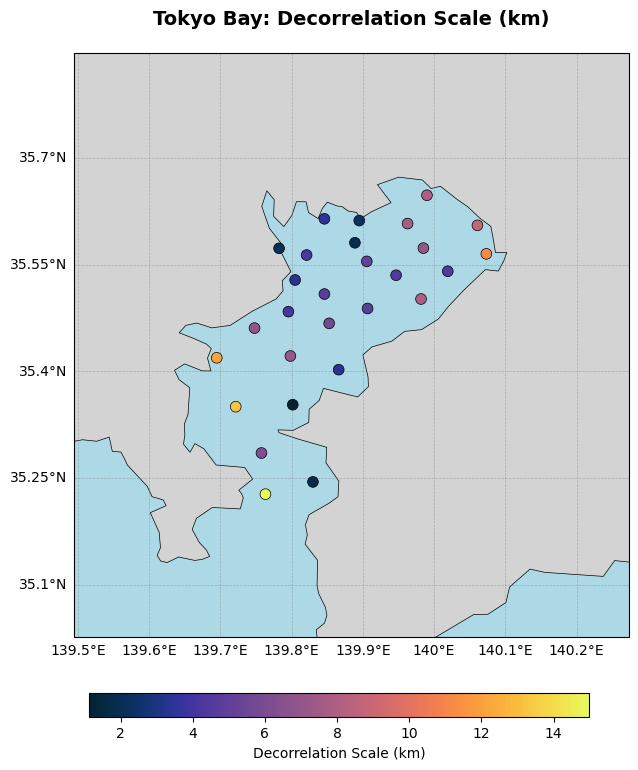

In [8]:
# Merge results with station coordinates for mapping
station_coords_wgs84 = bay_gdf[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode')
plot_data = station_coords_wgs84.merge(results_df, left_on='zettaicode', right_on='Station_ID')

# Map extent
bounds = bay_gdf.total_bounds
map_extent = [bounds[0] - 0.2, bounds[2] + 0.2, bounds[1] - 0.2, bounds[3] + 0.2]

# Load GEBCO bathymetry (optional — skip if not available)
try:
    import xarray as xr
    gebco_path = ProjectPaths.BOUNDARIES_DIR / "gebco_2024_n35.5_s34.0_w139.0_e140.5.nc"
    gebco = xr.open_dataset(gebco_path)
    has_gebco = True
except:
    has_gebco = False

# Create figure
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN)

# Cartopy land and coastline (no SIS shapefile for Tokyo Bay)
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# GEBCO bathymetry background
if has_gebco:
    bath = gebco['elevation'].values
    lons = gebco['lon'].values
    lats = gebco['lat'].values
    bath_masked = np.where(bath < 0, bath, np.nan)
    ax.pcolormesh(lons, lats, bath_masked, cmap=cmocean.cm.deep, 
                  transform=ccrs.PlateCarree(), zorder=0.1)

# Decorrelation scale scatter
sc = ax.scatter(
    plot_data['longitude'], plot_data['latitude'],
    c=plot_data['Decorrelation_Scale_km'],
    cmap=cmocean.cm.thermal,
    s=60, edgecolors='k', linewidths=0.5,
    transform=ccrs.PlateCarree(),
    zorder=MappingConfig.ZORDER_PREDICTED
)

# Gridlines
gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE,
                  color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA,
                  linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
gl.top_labels = False
gl.right_labels = False

ax.set_extent(map_extent, crs=ccrs.PlateCarree())
plt.title(f'{bay_name}: Decorrelation Scale (km)', pad=20, fontsize=14, fontweight='bold')

# Single colorbar for decorrelation scale only
plt.subplots_adjust(bottom=0.15)
cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])
cbar = fig.colorbar(sc, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Decorrelation Scale (km)')

plt.show()